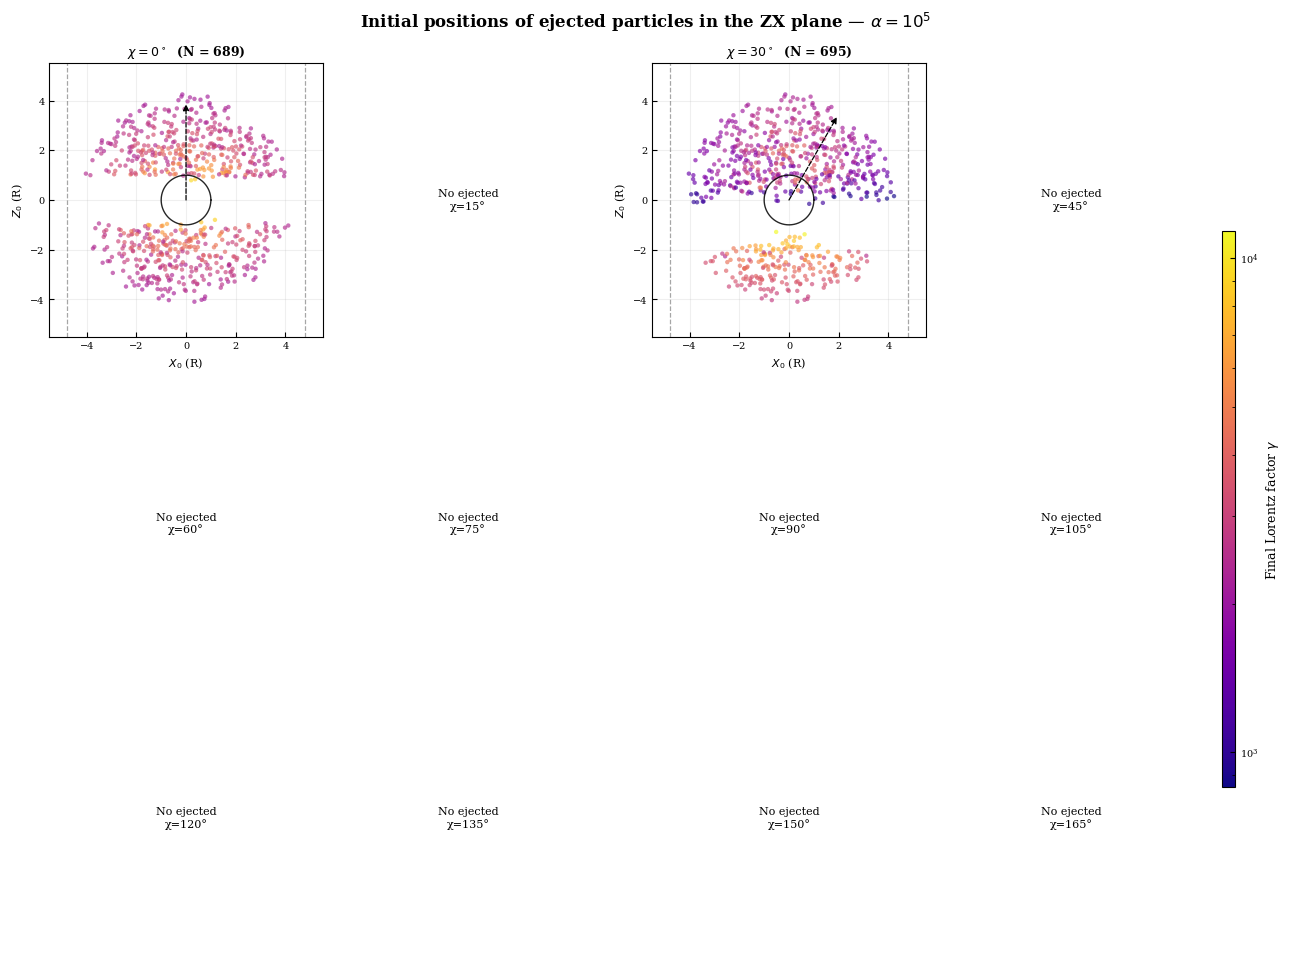

In [ ]:
# ==========================================
# GRADE 3×4 — PROJEÇÃO ZX A PARTIR DO CSV
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES = [0, 15, 30, 45, 60, 75,
          90, 105, 120, 135, 150, 165]

POINT_SIZE   = 10
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

om = 0.209
r_lc_val = 1.0 / om

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)

# Filtra alpha
df_alpha = df[df.alpha == ALPHA_VAL]

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

theta_circ = np.linspace(0, 2*np.pi, 400)
ZOOM_LIM = r_lc_val * 1.15

# Limites globais de gamma (para colorbar consistente)
d_all = df_alpha[df_alpha.status == "Ejected"]
if len(d_all):
    vmin = max(d_all.gamma_final.min(), 1.0)
    vmax = max(d_all.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]

    d = df_alpha[(df_alpha.angle_deg == ang) &
                 (df_alpha.status == "Ejected")]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\nχ={ang}°",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    x0    = d.x0.values
    z0    = d.z0.values
    gamas = d.gamma_final.values
    N = len(gamas)

    # Scatter em ZX
    ax.scatter(x0, z0, c=gamas, cmap=CMAP,
               norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Estrela
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='black', lw=1.0, alpha=0.85, zorder=4)

    # Light cylinder — retas verticais em ZX
    ax.axvline( r_lc_val, color='gray', ls='--', lw=0.9,
               alpha=0.7, zorder=2)
    ax.axvline(-r_lc_val, color='gray', ls='--', lw=0.9,
               alpha=0.7, zorder=2)

    # Seta do dipolo (direção (sin χ, cos χ) em ZX)
    chi_rad = np.radians(ang)
    L_dip = ZOOM_LIM * 0.7
    dx = np.sin(chi_rad) * L_dip
    dz = np.cos(chi_rad) * L_dip

    arrow = FancyArrowPatch(
        (0, 0), (dx, dz),
        arrowstyle='-|>', color='black',
        lw=0.9, linestyle='--', mutation_scale=9,
        shrinkA=0, shrinkB=0, zorder=5,
    )
    ax.add_patch(arrow)

    # Estética
    ax.set_xlabel(r'$X_0$ (R)', fontsize=8)
    ax.set_ylabel(r'$Z_0$ (R)', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {N})',
                 fontweight='bold', fontsize=9)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.2, zorder=0)
    ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
    ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP,
                           norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Initial positions of ejected particles in the ZX plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig('initial_positions.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)

plt.show()

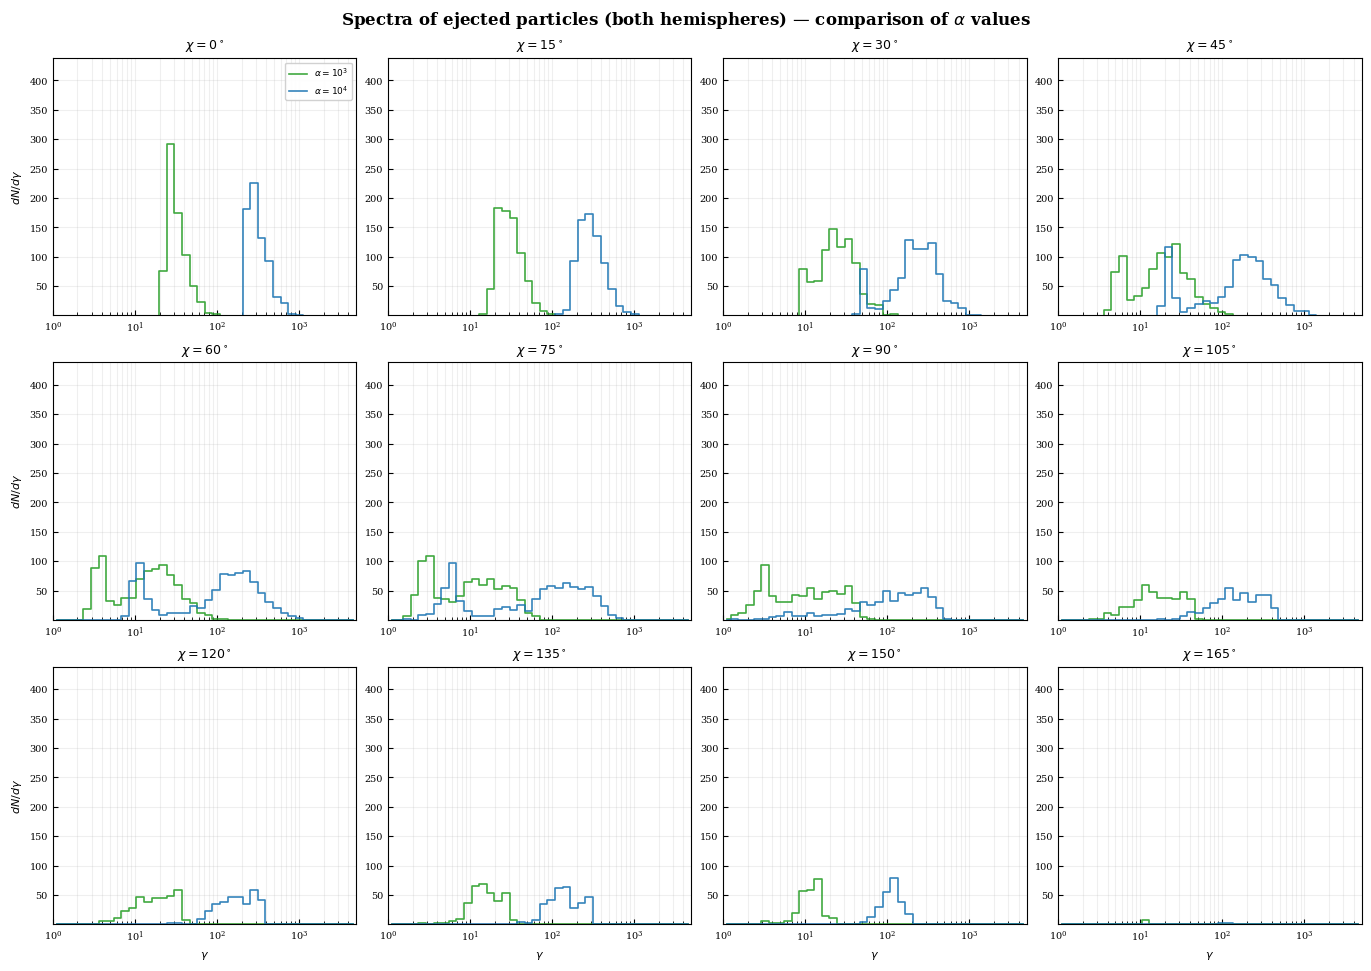

NameError: name 'out_png' is not defined

In [6]:
# ==========================================
# GRADE 3×4 — ESPECTROS SOBREPOSTOS (a partir do CSV)
# Personalizável: ALPHAS, HEMISPHERE
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO — EDITE AQUI
# ==========================================
CSV_FILE     = "particles_all_runs.csv"
ALPHAS       = [1000, 10000]   # qualquer subconjunto presente no CSV
HEMISPHERE   = "both"                     # "N" (z0>0), "S" (z0<0), "both"
ANGLES       = [0, 15, 30, 45, 60, 75,
                90, 105, 120, 135, 150, 165]

N_BINS       = 40
G_LO, G_HI   = 1.0, 5000.0

# Mapa de cores: escolhe automaticamente até 6 cores distintas
_COLOR_POOL = ['tab:green', 'tab:blue', 'tab:red',
               'tab:orange', 'tab:purple', 'tab:brown']
COLORS = {a: _COLOR_POOL[i % len(_COLOR_POOL)] for i, a in enumerate(ALPHAS)}

# ==========================================
# CARREGA CSV E FILTRA
# ==========================================
df = pd.read_csv(CSV_FILE)

# filtra alpha
df = df[df.alpha.isin(ALPHAS)]

# filtra hemisfério
if HEMISPHERE == "N":
    df = df[df.z0 > 0]
elif HEMISPHERE == "S":
    df = df[df.z0 < 0]
# "both" não filtra

# só ejetadas
df_ej = df[df.status == "Ejected"]

# ==========================================
# BINS COMUNS (log)
# ==========================================
LOG_EDGES = np.linspace(np.log10(G_LO), np.log10(G_HI), N_BINS + 1)
G_CENTERS = 10 ** (0.5 * (LOG_EDGES[:-1] + LOG_EDGES[1:]))

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.4 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

# ---------- Passo 1: histogramas ----------
hists = {a: {} for a in ALPHAS}
for ang in ANGLES:
    for a in ALPHAS:
        d = df_ej[(df_ej.angle_deg == ang) & (df_ej.alpha == a)]
        if len(d) == 0:
            hists[a][ang] = None
            continue
        g = d.gamma_final.values
        g_in = g[(g >= G_LO) & (g <= G_HI)]
        if len(g_in) == 0:
            hists[a][ang] = None
            continue
        hist, _ = np.histogram(np.log10(np.clip(g_in, 1.0, None)),
                               bins=LOG_EDGES)
        hists[a][ang] = hist

# ---------- Passo 2: ylim comum ----------
all_max = 1.0
for a in ALPHAS:
    for h in hists[a].values():
        if h is not None and h.max() > all_max:
            all_max = h.max()
Y_LO = 0.5
Y_HI = max(2.0, all_max * 1.5)

# ---------- Passo 3: plotar ----------
for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    has_any = False
    for a in ALPHAS:
        hist = hists[a].get(ang)
        if hist is None:
            continue
        has_any = True
        exp = int(round(np.log10(a)))
        # rótulo: se for potência exata de 10, usa notação científica; senão, número
        if 10**exp == a:
            label = rf'$\alpha = 10^{{{exp}}}$'
        else:
            label = rf'$\alpha = {a}$'
        ax.step(G_CENTERS, hist, where='mid',
                color=COLORS[a], lw=1.2, alpha=0.9, label=label)

    if not has_any:
        ax.text(0.5, 0.5, "No data",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8, color='red')
        ax.set_axis_off()
        continue

    ax.set_xscale('log')
    ax.set_xlim(G_LO, G_HI)
    ax.set_ylim(Y_LO, Y_HI)

    ax.set_title(rf'$\chi = {ang}^\circ$',
                 fontweight='bold', fontsize=9)

    if idx % N_COLS == 0:
        ax.set_ylabel(r'$dN/d\gamma$', fontsize=8)
    if idx >= (N_ROWS - 1) * N_COLS:
        ax.set_xlabel(r'$\gamma$', fontsize=8)

    ax.grid(True, alpha=0.2, which='both')
    ax.tick_params(labelsize=7)

    if idx == 0:
        ax.legend(loc='upper right', fontsize=6.5, framealpha=0.9)

# Título e nome do arquivo incluem hemisfério
hemi_label = {"N": "northern hemisphere",
              "S": "southern hemisphere",
              "both": "both hemispheres"}[HEMISPHERE]
fig.suptitle(rf'Spectra of ejected particles ({hemi_label}) — '
             rf'comparison of $\alpha$ values',
             fontsize=12, fontweight='bold')

out_pdf = f'spectra_comparison_{HEMISPHERE}.pdf'
plt.savefig(out_pdf, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: {out_pdf}, {out_png}")

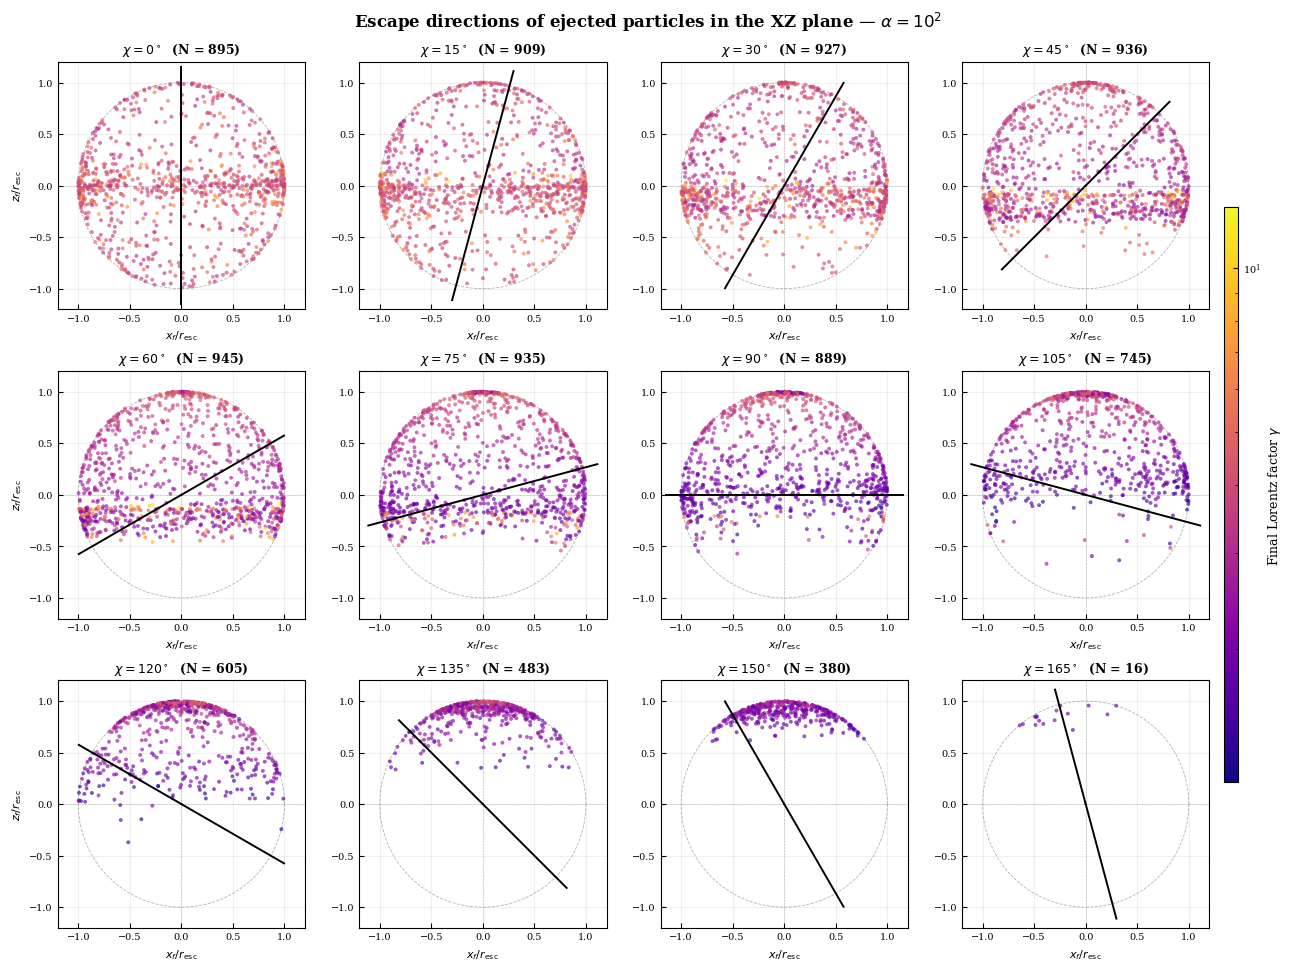

In [18]:
# ==========================================
# GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE (a partir do CSV)
# α fixo, 12 ângulos, cor = gamma final
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 100
ANGLES    = [0, 15, 30, 45, 60, 75,
             90, 105, 120, 135, 150, 165]

POINT_SIZE   = 8
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)
df_alpha = df[(df.alpha == ALPHA_VAL) & (df.status == "Ejected")].copy()

# Limites globais de gamma para colorbar consistente
if len(df_alpha):
    vmin = max(df_alpha.gamma_final.min(), 1.0)
    vmax = max(df_alpha.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_alpha[df_alpha.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    # Direções finais normalizadas (unidade: esfera)
    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = d.xf / r_norm
    zf_n = d.zf / r_norm

    # Scatter em XZ, cor = gamma_final
    ax.scatter(xf_n, zf_n,
               c=d.gamma_final.values,
               cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Círculo unitário (esfera de escape normalizada)
    theta_circ = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    # Eixo magnético (direção (sin χ, cos χ) em XZ)
    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=4)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=4)

    # Linhas guia (equador e eixo de rotação)
    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    # Estética
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP,
                           norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig(f'escape_directions_alpha{ALPHA_VAL}.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

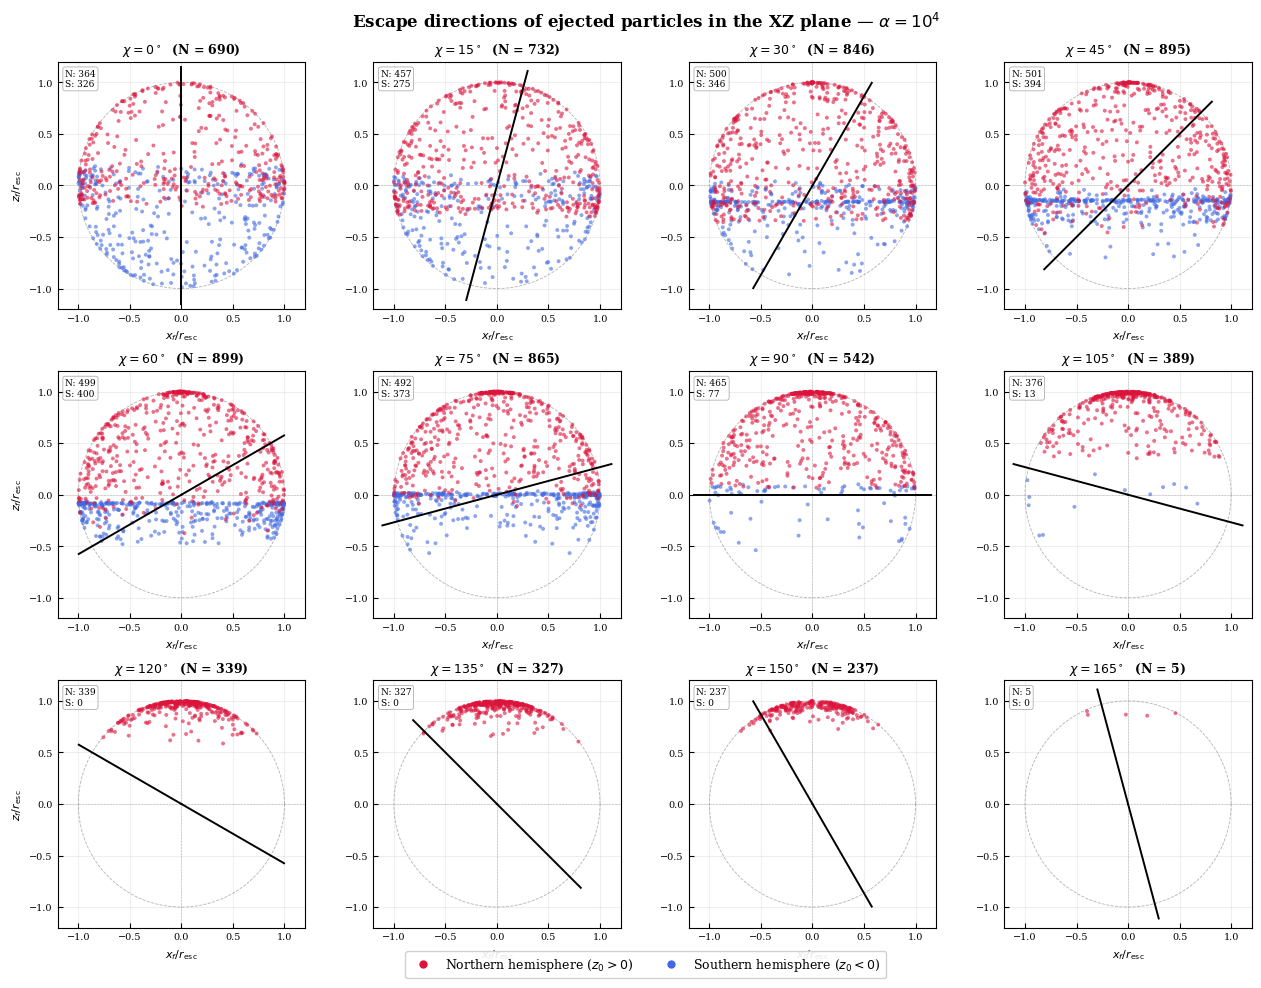

In [ ]:
# ==========================================
# GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE (a partir do CSV)
# Cor = hemisfério de origem (N=vermelho, S=azul)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ==========================================
# CONFIGURAÇÃO
# ==========================================
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES    = [0, 15, 30, 45, 60, 75,
             90, 105, 120, 135, 150, 165]

POINT_SIZE   = 8
POINT_ALPHA  = 0.6
MARKER_EDGE  = 'none'

COLOR_N = 'crimson'     # norte
COLOR_S = 'royalblue'   # sul

# ==========================================
# CARREGA CSV
# ==========================================
df = pd.read_csv(CSV_FILE)
df_alpha = df[(df.alpha == ALPHA_VAL) & (df.status == "Ejected")].copy()

# fallback: se a coluna 'hemisphere' não existir, cria a partir de z0
if "hemisphere" not in df_alpha.columns:
    df_alpha["hemisphere"] = np.where(df_alpha.z0 > 0, "N",
                              np.where(df_alpha.z0 < 0, "S", "E"))

# ==========================================
# LAYOUT 3×4
# ==========================================
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_alpha[df_alpha.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    # Direções finais normalizadas
    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = (d.xf / r_norm).values
    zf_n = (d.zf / r_norm).values
    hemi = d.hemisphere.values

    mask_N = (hemi == "N")
    mask_S = (hemi == "S")
    n_N = int(mask_N.sum())
    n_S = int(mask_S.sum())

    # Scatter: N em vermelho, S em azul
    ax.scatter(xf_n[mask_S], zf_n[mask_S],
               s=POINT_SIZE, c=COLOR_S, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)
    ax.scatter(xf_n[mask_N], zf_n[mask_N],
               s=POINT_SIZE, c=COLOR_N, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=4)

    # Círculo unitário (esfera de escape normalizada)
    theta_circ = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    # Eixo magnético (direção (sin χ, cos χ) em XZ)
    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=5)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.4, zorder=5)

    # Linhas guia
    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    # Estética
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

    # Contagem N/S no canto
    ax.text(0.03, 0.97,
            f"N: {n_N}\nS: {n_S}",
            transform=ax.transAxes, ha='left', va='top',
            fontsize=6.5, color='k',
            bbox=dict(boxstyle='round,pad=0.25',
                      facecolor='white', edgecolor='gray',
                      alpha=0.75, linewidth=0.5),
            zorder=6)

# Legenda global (uma vez, no canto inferior)
legend_handles = [
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=COLOR_N, markeredgecolor='none',
           markersize=6, label='Northern hemisphere ($z_0 > 0$)'),
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=COLOR_S, markeredgecolor='none',
           markersize=6, label='Southern hemisphere ($z_0 < 0$)'),
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=2, fontsize=9, frameon=True, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.02))

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig(f'escape_directions_hemisphere_alpha{ALPHA_VAL}.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

In [3]:
# =========================================================
# append_alpha.py
# Adiciona incrementalmente os .pkl de um alpha ao CSV
# Rodar várias vezes é seguro: só adiciona o que falta.
# =========================================================
import os
import re
import pickle
import numpy as np
import pandas as pd

# ---------- Configuração ----------
CSV_FILE    = "particles_all_runs.csv"
RESULTS_DIR = "."
ALPHA_NEW   = 100000          # mude conforme o alpha que está rodando
PATTERN     = re.compile(rf"results_angle_(\d+)_alpha{ALPHA_NEW}\.pkl")
STATUSES    = ["Crashed", "Ejected", "Trapped"]

# ---------- Carrega CSV existente ----------
if os.path.isfile(CSV_FILE):
    df_old = pd.read_csv(CSV_FILE)
    print(f"CSV existente: {len(df_old)} linhas")
    print(f"  alphas: {sorted(df_old.alpha.unique())}")
    print(f"  (alpha, angle) já presentes: "
          f"{sorted(df_old[df_old.alpha == ALPHA_NEW].angle_deg.unique())}")
else:
    df_old = pd.DataFrame()
    print(f"CSV não existe ainda; será criado.")

# Ângulos já no CSV para esse alpha
if len(df_old) and ALPHA_NEW in df_old.alpha.unique():
    angles_done = set(df_old[df_old.alpha == ALPHA_NEW].angle_deg.unique())
else:
    angles_done = set()

# ---------- Encontra os .pkl disponíveis ----------
files = sorted(f for f in os.listdir(RESULTS_DIR) if PATTERN.match(f))
print(f"\nArquivos .pkl para alpha={ALPHA_NEW}: {len(files)}")

records = []
skipped = []
for fname in files:
    m = PATTERN.match(fname)
    angle_deg = int(m.group(1))

    if angle_deg in angles_done:
        skipped.append(angle_deg)
        continue

    fpath = os.path.join(RESULTS_DIR, fname)
    with open(fpath, "rb") as f:
        data = pickle.load(f)

    if not isinstance(data, dict):
        print(f"[skip] formato inesperado: {fname}")
        continue

    # Verifica se o .pkl tem t_final
    has_t = ("t_final" in data.get("Ejected", {}))

    n_this = 0
    for status in STATUSES:
        if status not in data:
            continue
        block = data[status]
        xs   = block.get("x", [])
        ys   = block.get("y", [])
        zs   = block.get("z", [])
        xfs  = block.get("xf", [])
        yfs  = block.get("yf", [])
        zfs  = block.get("zf", [])
        gs   = block.get("gamas", [])
        ts   = block.get("t_final", [np.nan] * len(xs)) if has_t else [np.nan] * len(xs)

        n = len(xs)
        for i in range(n):
            if i < len(ys) and hasattr(ys[i], "__len__") and len(ys[i]) >= 3:
                x0, y0, z0 = float(ys[i][0]), float(ys[i][1]), float(ys[i][2])
            else:
                x0, y0, z0 = float(xs[i]), 0.0, float(zs[i])

            xf = float(xfs[i]) if i < len(xfs) else np.nan
            yf = float(yfs[i]) if i < len(yfs) else np.nan
            zf = float(zfs[i]) if i < len(zfs) else np.nan
            gf = float(gs[i])  if i < len(gs)  else np.nan
            tf = float(ts[i])  if i < len(ts)  else np.nan

            r0 = float(np.sqrt(x0**2 + y0**2 + z0**2))
            cos_t = z0 / r0 if r0 > 0 else np.nan
            theta0 = float(np.degrees(np.arccos(np.clip(cos_t, -1, 1)))) \
                     if np.isfinite(cos_t) else np.nan
            phi0 = float(np.degrees(np.arctan2(y0, x0)))
            rf = float(np.sqrt(xf**2 + yf**2 + zf**2)) \
                 if np.isfinite(xf) else np.nan

            records.append({
                "alpha": ALPHA_NEW,
                "angle_deg": angle_deg,
                "status": status,
                "particle_id_local": i,
                "x0": x0, "y0": y0, "z0": z0,
                "r0": r0,
                "theta0_deg": theta0,
                "phi0_deg": phi0,
                "hemisphere": ("N" if z0 > 0 else ("S" if z0 < 0 else "E")),
                "xf": xf, "yf": yf, "zf": zf, "rf": rf,
                "gamma_final": gf,
                "t_final": tf,
            })
            n_this += 1

    print(f"  [ok] angle={angle_deg:3d}: {n_this} partículas adicionadas")

if skipped:
    print(f"\nÂngulos já presentes (pulados): {sorted(skipped)}")

if not records:
    print("\nNada novo para adicionar. CSV inalterado.")
else:
    df_new = pd.DataFrame.from_records(records)
    df = pd.concat([df_old, df_new], ignore_index=True)

    # Recalcula uid (útil para rastrear partículas entre alphas)
    df["uid"] = (df[["x0","y0","z0"]].round(6).astype(str).agg("|".join, axis=1))

    df.to_csv(CSV_FILE, index=False)
    print(f"\nSalvo: {CSV_FILE}  ({len(df)} linhas no total)")
    print(f"  Linhas adicionadas: {len(df_new)}")
    print(f"  Alphas no CSV: {sorted(df.alpha.unique())}")
    print("\nResumo por (alpha, angle, status):")
    print(df.groupby(["alpha","angle_deg","status"]).size()
            .unstack(fill_value=0))

CSV existente: 43000 linhas
  alphas: [100, 1000, 3000, 10000]
  (alpha, angle) já presentes: []

Arquivos .pkl para alpha=100000: 2
  [ok] angle=  0: 1000 partículas adicionadas
  [ok] angle= 30: 1000 partículas adicionadas

Salvo: particles_all_runs.csv  (45000 linhas no total)
  Linhas adicionadas: 2000
  Alphas no CSV: [100, 1000, 3000, 10000, 100000]

Resumo por (alpha, angle, status):
status            Crashed  Ejected  Trapped
alpha  angle_deg                           
100    0                7      895       98
       15               7      909       84
       30               9      927       64
       45              15      936       49
       60              16      945       39
       75              22      935       43
       90              39      889       72
       105             63      745      192
       120             91      605      304
       135            112      483      405
       150            147      380      473
       165            204       16

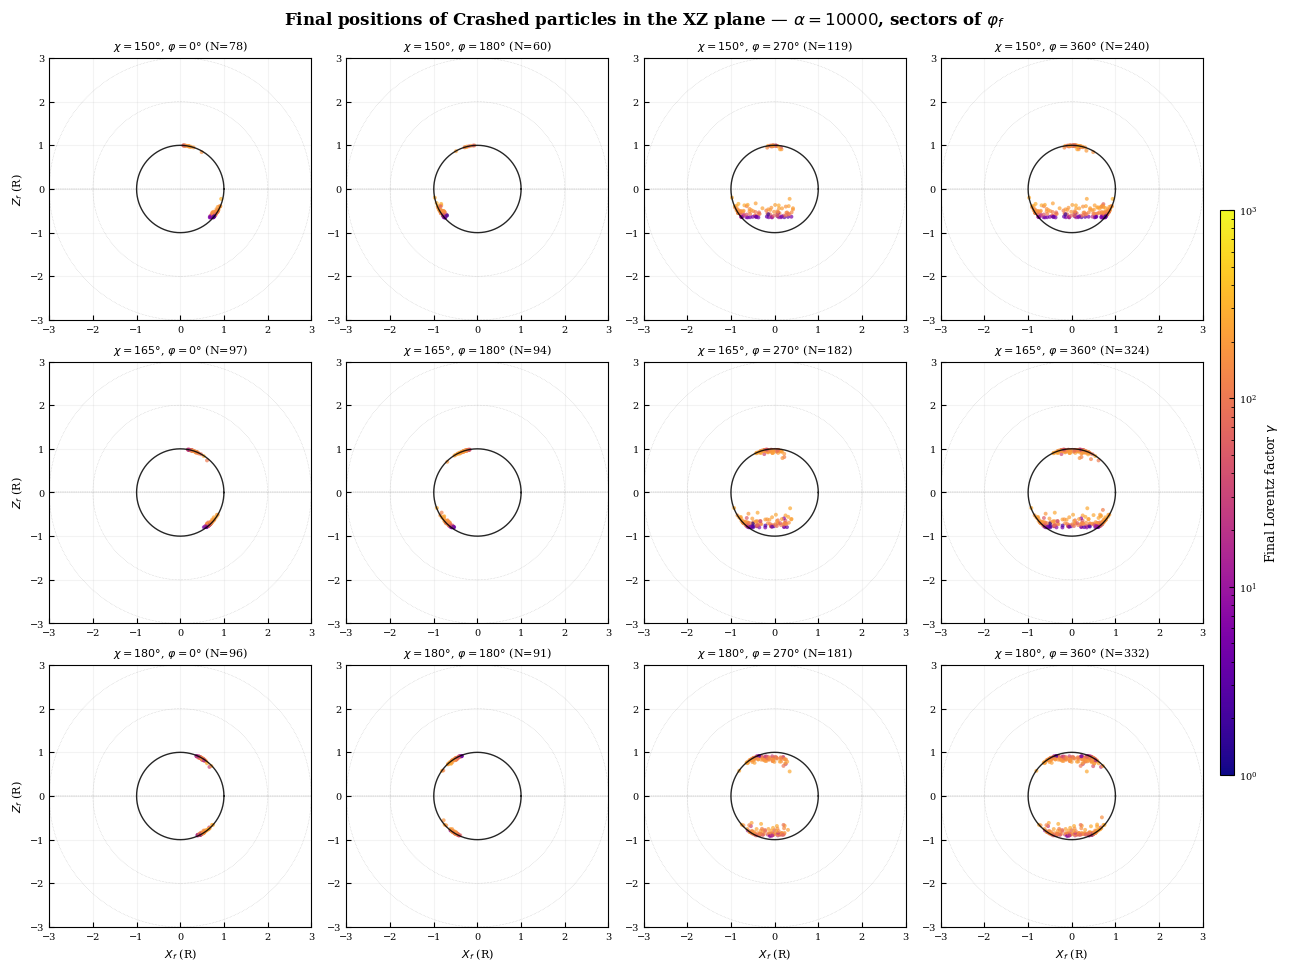

In [4]:
# =========================================================
# HOTSPOTS de partículas Trapped — grade 3×4
# Linhas: χ = 150, 165, 180
# Colunas: setores de φ (0, 60, 120, 180)
# Projeção XZ
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
STATUS    = "Crashed"          # "Trapped" ou "Crashed"
ANGLES    = [150,165,180]    # linhas
PHI_CENTERS = [0, 180,270,360]  # colunas (graus)
PHI_WIDTH   = 60               # largura do setor (graus)

# Qual φ usar para o setor: "phi_i" (inicial) ou "phi_f" (final)
PHI_USE = "phi_f"

R = 1.0                        # raio da estrela
ZOOM_LIM = 3.0                 # limite do plot (em R)

# ---------- Carrega CSV ----------
df = pd.read_csv(CSV_FILE)

# Calcula φ inicial e final se não estiverem no CSV
if "phi_i" not in df.columns:
    df["phi_i"] = np.degrees(np.arctan2(df.y0, df.x0))
if "phi_f" not in df.columns:
    df["phi_f"] = np.degrees(np.arctan2(df.yf, df.xf))

phi_col = "phi_i" if PHI_USE == "phi_i" else "phi_f"

# ---------- Layout 3×4 ----------
N_ROWS = len(ANGLES)
N_COLS = len(PHI_CENTERS)

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
if N_ROWS == 1:
    axes = axes.reshape(1, -1)

theta_circ = np.linspace(0, 2*np.pi, 400)

for i, ang in enumerate(ANGLES):
    for j, phi_c in enumerate(PHI_CENTERS):
        ax = axes[i, j]

        # Filtra: ângulo, alpha, status
        d = df[(df.angle_deg == ang) &
               (df.alpha == ALPHA_VAL) &
               (df.status == STATUS)].copy()

        if len(d) == 0:
            ax.text(0.5, 0.5, f"No {STATUS}\nχ={ang}°",
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=8)
            ax.set_axis_off()
            continue

        # Filtra pelo setor de phi
        phi_lo = phi_c - PHI_WIDTH / 2
        phi_hi = phi_c + PHI_WIDTH / 2
        # Ajusta para o intervalo [-180, 180]
        if phi_hi > 180:
            mask = (d[phi_col] >= phi_lo) | (d[phi_col] < phi_hi - 360)
        elif phi_lo < -180:
            mask = (d[phi_col] >= phi_lo + 360) | (d[phi_col] < phi_hi)
        else:
            mask = (d[phi_col] >= phi_lo) & (d[phi_col] < phi_hi)

        ds = d[mask]

        if len(ds) == 0:
            ax.text(0.5, 0.5, "Empty sector",
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=7, color='gray')
            # Desenha a estrela mesmo assim
            ax.plot(np.cos(theta_circ), np.sin(theta_circ),
                    color='black', lw=1.0, alpha=0.6)
            ax.set_aspect('equal')
            ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
            ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
            ax.grid(True, alpha=0.15)
            ax.set_title(rf"$\chi={ang}°$, $\varphi={phi_c}°$ (N=0)",
                         fontsize=8)
            continue

        # Scatter em XZ (posição final)
        xf = ds.xf.values
        zf = ds.zf.values
        rf = np.sqrt(xf**2 + zf**2 + ds.yf.values**2)
        gamma = ds.gamma_final.values

        # Cor por log10(gamma)
        sc = ax.scatter(xf, zf, c=np.log10(np.clip(gamma, 1, None)),
                        cmap='plasma', s=8, alpha=0.7,
                        edgecolors='none', vmin=0, vmax=3)

        # Estrela
        ax.plot(np.cos(theta_circ), np.sin(theta_circ),
                color='black', lw=1.0, alpha=0.85, zorder=4)

        # Círculo de referência (r = 2R, por exemplo)
        for rref in [2.0, 3.0]:
            ax.plot(rref*np.cos(theta_circ), rref*np.sin(theta_circ),
                    color='gray', lw=0.4, ls=':', alpha=0.5, zorder=1)

        # Linha do equador
        ax.axhline(0, color='k', lw=0.3, ls='--', alpha=0.4, zorder=1)

        # Estética
        ax.set_aspect('equal')
        ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
        ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
        ax.grid(True, alpha=0.15, zorder=0)
        ax.set_title(rf"$\chi={ang}°$, $\varphi={phi_c}°$ (N={len(ds)})",
                     fontsize=8)
        if j == 0:
            ax.set_ylabel(r"$Z_f$ (R)", fontsize=8)
        if i == N_ROWS - 1:
            ax.set_xlabel(r"$X_f$ (R)", fontsize=8)

# Colorbar
sm = plt.cm.ScalarMappable(cmap='plasma', norm=LogNorm(vmin=1, vmax=1000))
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes.ravel().tolist(),
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(rf"Final positions of {STATUS} particles in the XZ plane — "
             rf"$\alpha = {ALPHA_VAL}$, sectors of $\varphi_{{{PHI_USE[-1]}}}$",
             fontsize=12, fontweight='bold')

plt.savefig(f"hotspots_{STATUS}_alpha{ALPHA_VAL}.pdf",
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

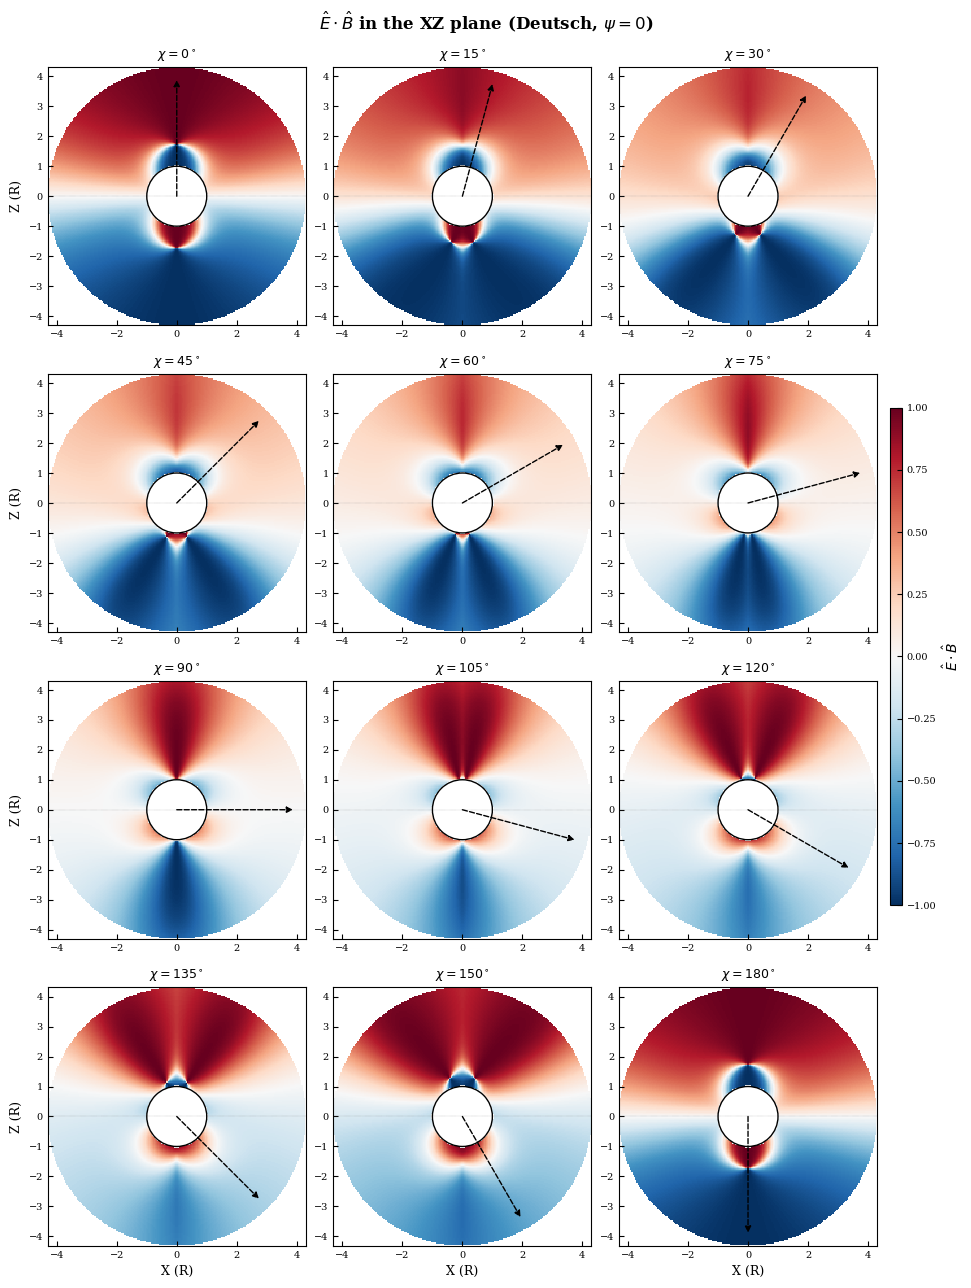

Salvo: EB_map_grid.pdf


In [1]:
# =========================================================
# MAPA DE CALOR DE Ê·B̂ — grade 4×3
# 12 ângulos (0 a 180, exceto 165), plano XZ
# =========================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

# ---------- Importa o campo do simulation.py ----------
import simulation
from simulation import EM_Deutsch, R, r_lc

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# =========================================================
# CONFIGURAÇÃO
# =========================================================
ANGLES   = [0, 15, 30, 45, 60, 75,
            90, 105, 120, 135, 150, 180]   # sem 165
NGRID    = 200
R_MIN    = 1.02
R_MAX    = 0.9 * r_lc
OUT_PDF  = "EB_map_grid.pdf"

# =========================================================
# AVALIAÇÃO DO CAMPO EM GRADE
# =========================================================
def EB_norm_map(angle_deg, n=NGRID, r_min=R_MIN, r_max=R_MAX):
    """
    Retorna X, Z, EBn onde EBn = (E·B)/(|E||B|), avaliado em psi=0.
    """
    x = np.linspace(-r_max, r_max, n)
    z = np.linspace(-r_max, r_max, n)
    X, Z = np.meshgrid(x, z)
    Y = np.zeros_like(X)

    r = np.sqrt(X**2 + Y**2 + Z**2)
    inside = (r >= r_min) & (r <= r_max)

    EBn = np.full_like(X, np.nan)
    Xt = np.radians(angle_deg)

    for i in range(n):
        for j in range(n):
            if not inside[i, j]:
                continue
            Ex, Ey, Ez, Bx, By, Bz = EM_Deutsch(X[i, j], Y[i, j], Z[i, j],
                                                0.0, Xt)
            E = np.array([Ex, Ey, Ez])
            B = np.array([Bx, By, Bz])
            nE = np.linalg.norm(E)
            nB = np.linalg.norm(B)
            if nE > 0 and nB > 0:
                EBn[i, j] = np.dot(E, B) / (nE * nB)
    return X, Z, EBn

# =========================================================
# PLOT
# =========================================================
N_ROWS = 4
N_COLS = 3

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

norm = Normalize(vmin=-1, vmax=1)
theta_circ = np.linspace(0, 2*np.pi, 400)

for k, ang in enumerate(ANGLES):
    ax = axes[k]
    X, Z, EBn = EB_norm_map(ang)

    im = ax.pcolormesh(X, Z, EBn, shading="auto",
                       cmap="RdBu_r", norm=norm, rasterized=True)

    # Estrela
    ax.add_patch(plt.Circle((0, 0), R, color="k", fill=False, lw=1.0,
                            zorder=4))

    # Eixo de rotação (z)
    ax.axhline(0, color="gray", lw=0.3, ls=":", zorder=2)

    # Eixo magnético (seta tracejada na direção do dipolo)
    chi_rad = np.radians(ang)
    L = R_MAX * 0.9
    arrow = FancyArrowPatch(
        (0, 0), (L*np.sin(chi_rad), L*np.cos(chi_rad)),
        arrowstyle='-|>', color='k', lw=1.0, ls='--',
        mutation_scale=9, shrinkA=0, shrinkB=0, zorder=5,
    )
    ax.add_patch(arrow)

    # Estética
    ax.set_aspect("equal")
    ax.set_xlim(-R_MAX, R_MAX)
    ax.set_ylim(-R_MAX, R_MAX)
    ax.set_title(rf"$\chi = {ang}^\circ$", fontsize=9)
    ax.tick_params(labelsize=7)
    if k % N_COLS == 0:
        ax.set_ylabel("Z (R)")
    if k >= (N_ROWS - 1) * N_COLS:
        ax.set_xlabel("X (R)")

# Colorbar
sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, fraction=0.015, pad=0.015, aspect=40)
cbar.set_label(r"$\hat{E}\cdot\hat{B}$", fontsize=10)

fig.suptitle(r"$\hat{E}\cdot\hat{B}$ in the XZ plane (Deutsch, $\psi=0$)",
             fontsize=12, fontweight='bold')

plt.savefig(OUT_PDF, bbox_inches="tight", pad_inches=0.05)
plt.show()
print(f"Salvo: {OUT_PDF}")

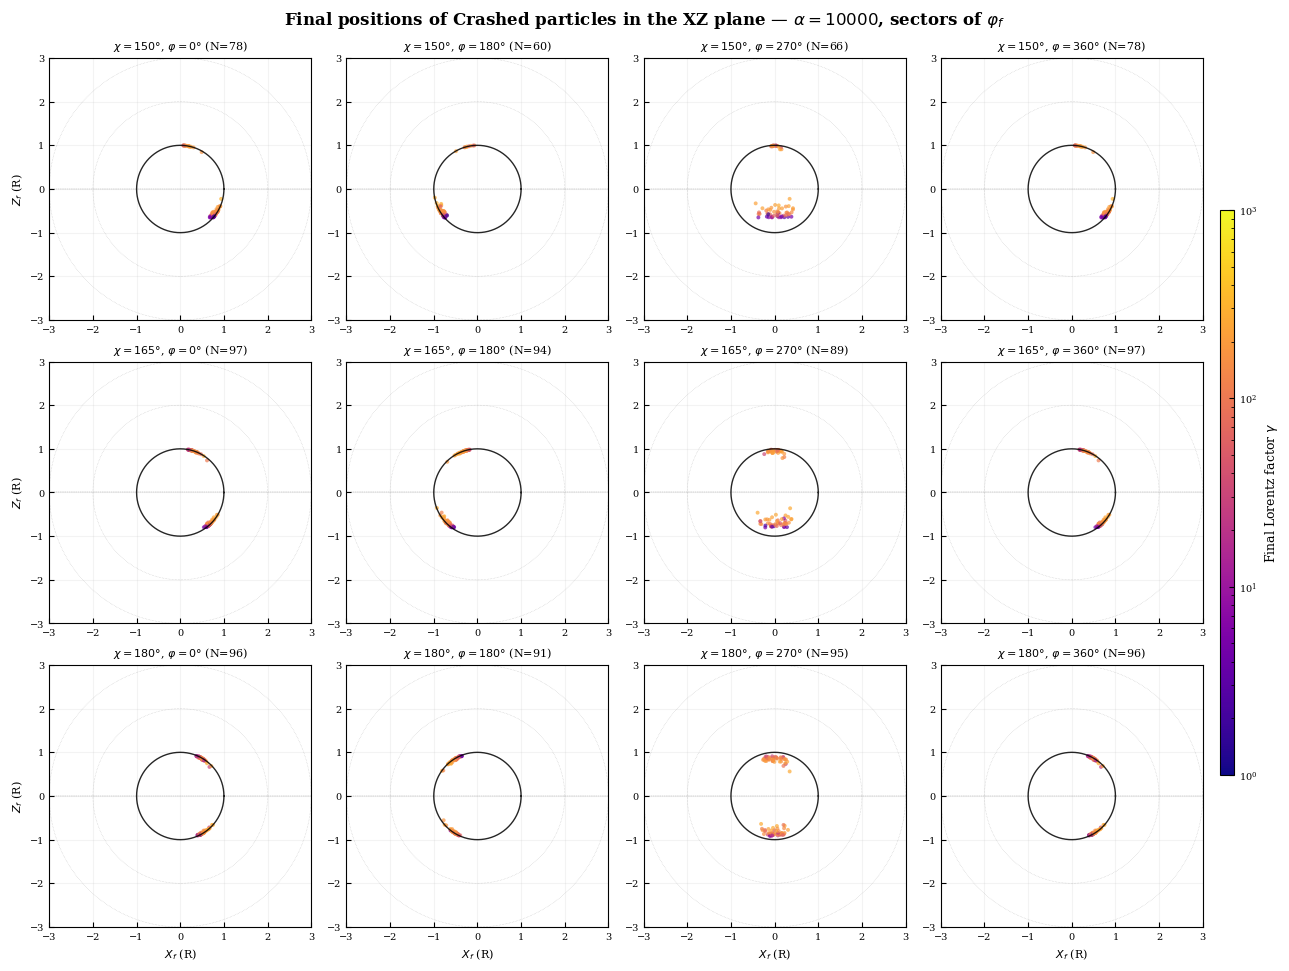

In [7]:
# =========================================================
# HOTSPOTS de partículas Trapped — grade 3×4
# Linhas: χ = 150, 165, 180
# Colunas: setores de φ (0, 60, 120, 180)
# Projeção XZ
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
STATUS    = "Crashed"          # "Trapped" ou "Crashed"
ANGLES    = [150,165,180]    # linhas
PHI_CENTERS = [0, 180,270,360]  # colunas (graus)
PHI_WIDTH   = 60               # largura do setor (graus)

# Qual φ usar para o setor: "phi_i" (inicial) ou "phi_f" (final)
PHI_USE = "phi_f"

R = 1.0                        # raio da estrela
ZOOM_LIM = 3.0                 # limite do plot (em R)

# ---------- Carrega CSV ----------
df = pd.read_csv(CSV_FILE)

# Calcula φ inicial e final se não estiverem no CSV
if "phi_i" not in df.columns:
    df["phi_i"] = np.degrees(np.arctan2(df.y0, df.x0))
if "phi_f" not in df.columns:
    df["phi_f"] = np.degrees(np.arctan2(df.yf, df.xf))

phi_col = "phi_i" if PHI_USE == "phi_i" else "phi_f"

# ---------- Layout 3×4 ----------
N_ROWS = len(ANGLES)
N_COLS = len(PHI_CENTERS)

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
if N_ROWS == 1:
    axes = axes.reshape(1, -1)

theta_circ = np.linspace(0, 2*np.pi, 400)

for i, ang in enumerate(ANGLES):
    for j, phi_c in enumerate(PHI_CENTERS):
        ax = axes[i, j]

        # Filtra: ângulo, alpha, status
        d = df[(df.angle_deg == ang) &
               (df.alpha == ALPHA_VAL) &
               (df.status == STATUS)].copy()

        if len(d) == 0:
            ax.text(0.5, 0.5, f"No {STATUS}\nχ={ang}°",
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=8)
            ax.set_axis_off()
            continue

        # Filtra pelo setor de phi (normalizado para [0, 360))
        phi_vals = d[phi_col].values % 360.0

        phi_c_norm = phi_c % 360.0
        phi_lo = (phi_c_norm - PHI_WIDTH / 2) % 360.0
        phi_hi = (phi_c_norm + PHI_WIDTH / 2) % 360.0

        if phi_lo < phi_hi:
            mask = (phi_vals >= phi_lo) & (phi_vals < phi_hi)
        else:
            # setor cruza 0/360
            mask = (phi_vals >= phi_lo) | (phi_vals < phi_hi)

        ds = d[mask]

        if len(ds) == 0:
            ax.text(0.5, 0.5, "Empty sector",
                    ha='center', va='center', transform=ax.transAxes,
                    fontsize=7, color='gray')
            # Desenha a estrela mesmo assim
            ax.plot(np.cos(theta_circ), np.sin(theta_circ),
                    color='black', lw=1.0, alpha=0.6)
            ax.set_aspect('equal')
            ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
            ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
            ax.grid(True, alpha=0.15)
            ax.set_title(rf"$\chi={ang}°$, $\varphi={phi_c}°$ (N=0)",
                         fontsize=8)
            continue

        # Scatter em XZ (posição final)
        xf = ds.xf.values
        zf = ds.zf.values
        rf = np.sqrt(xf**2 + zf**2 + ds.yf.values**2)
        gamma = ds.gamma_final.values

        # Cor por log10(gamma)
        sc = ax.scatter(xf, zf, c=np.log10(np.clip(gamma, 1, None)),
                        cmap='plasma', s=8, alpha=0.7,
                        edgecolors='none', vmin=0, vmax=3)

        # Estrela
        ax.plot(np.cos(theta_circ), np.sin(theta_circ),
                color='black', lw=1.0, alpha=0.85, zorder=4)

        # Círculo de referência (r = 2R, por exemplo)
        for rref in [2.0, 3.0]:
            ax.plot(rref*np.cos(theta_circ), rref*np.sin(theta_circ),
                    color='gray', lw=0.4, ls=':', alpha=0.5, zorder=1)

        # Linha do equador
        ax.axhline(0, color='k', lw=0.3, ls='--', alpha=0.4, zorder=1)

        # Estética
        ax.set_aspect('equal')
        ax.set_xlim(-ZOOM_LIM, ZOOM_LIM)
        ax.set_ylim(-ZOOM_LIM, ZOOM_LIM)
        ax.grid(True, alpha=0.15, zorder=0)
        ax.set_title(rf"$\chi={ang}°$, $\varphi={phi_c}°$ (N={len(ds)})",
                     fontsize=8)
        if j == 0:
            ax.set_ylabel(r"$Z_f$ (R)", fontsize=8)
        if i == N_ROWS - 1:
            ax.set_xlabel(r"$X_f$ (R)", fontsize=8)

# Colorbar
sm = plt.cm.ScalarMappable(cmap='plasma', norm=LogNorm(vmin=1, vmax=1000))
sm.set_array([])

cbar = fig.colorbar(sm, ax=axes.ravel().tolist(),
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(rf"Final positions of {STATUS} particles in the XZ plane — "
             rf"$\alpha = {ALPHA_VAL}$, sectors of $\varphi_{{{PHI_USE[-1]}}}$",
             fontsize=12, fontweight='bold')

plt.savefig(f"hotspots_{STATUS}_alpha{ALPHA_VAL}.pdf",
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()

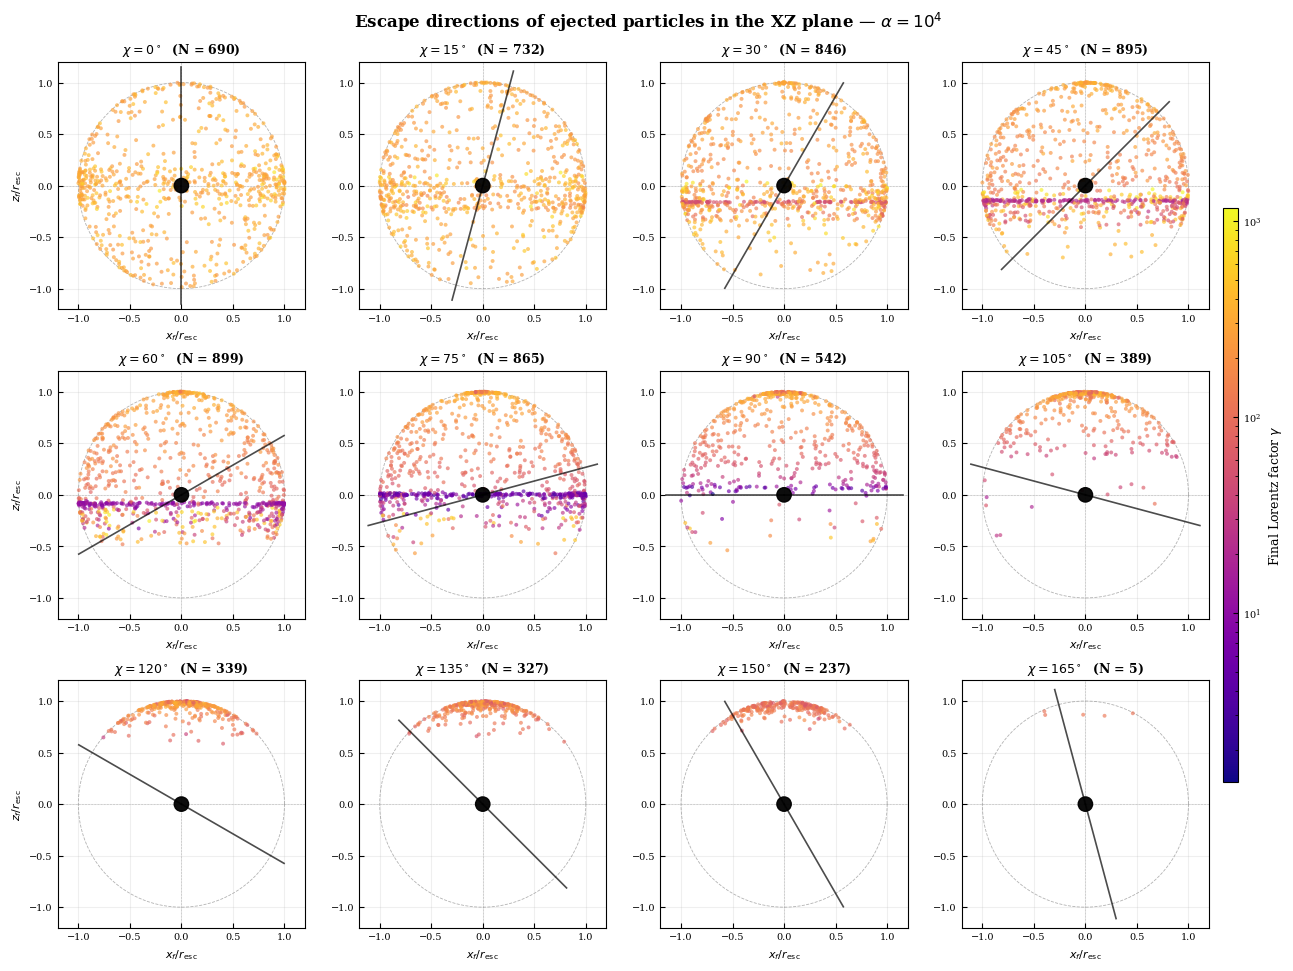

Salvo: escape_directions_alpha10000_with_star.pdf


In [1]:
# ==========================================
# GRADE 3×4 — DIREÇÕES FINAIS DE ESCAPE + ESTRELA
# α fixo, 12 ângulos, cor = gamma final
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 8,
    'font.family': 'serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
})

# ---------- Configuração ----------
CSV_FILE  = "particles_all_runs.csv"
ALPHA_VAL = 10000
ANGLES    = [0, 15, 30, 45, 60, 75,
             90, 105, 120, 135, 150, 165]

POINT_SIZE   = 8
POINT_ALPHA  = 0.65
CMAP         = 'plasma'
MARKER_EDGE  = 'none'

# ---------- Carrega CSV ----------
df = pd.read_csv(CSV_FILE)
df_alpha = df[(df.alpha == ALPHA_VAL) & (df.status == "Ejected")].copy()

if len(df_alpha):
    vmin = max(df_alpha.gamma_final.min(), 1.0)
    vmax = max(df_alpha.gamma_final.max(), vmin * 1.001)
else:
    vmin, vmax = 1.0, 1000.0

# ---------- Layout 3×4 ----------
N_ROWS = 3
N_COLS = 4

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

# Raio da estrela em unidades de r_esc (r_esc = 3 r_lc ≈ 14.35, R = 1)
r_esc = 3.0 / 0.209
R_norm = 1.0 / r_esc   # raio da estrela normalizado pela esfera de escape

theta_circ = np.linspace(0, 2*np.pi, 400)

for idx, ang in enumerate(ANGLES):
    ax = axes[idx]
    d = df_alpha[df_alpha.angle_deg == ang]

    if len(d) == 0:
        ax.text(0.5, 0.5, f"No ejected\n$\\chi={ang}^\\circ$",
                ha='center', va='center', transform=ax.transAxes,
                fontsize=8)
        ax.set_axis_off()
        continue

    # Direções finais normalizadas
    r_norm = np.sqrt(d.xf**2 + d.yf**2 + d.zf**2)
    xf_n = d.xf / r_norm
    zf_n = d.zf / r_norm

    # Scatter em XZ
    ax.scatter(xf_n, zf_n,
               c=d.gamma_final.values,
               cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax),
               s=POINT_SIZE, alpha=POINT_ALPHA,
               edgecolors=MARKER_EDGE, linewidths=0, zorder=3)

    # Círculo unitário (esfera de escape)
    ax.plot(np.cos(theta_circ), np.sin(theta_circ),
            color='gray', lw=0.6, ls='--', alpha=0.6, zorder=2)

    # Estrela preta no centro (raio R_norm)
    ax.add_patch(plt.Circle((0, 0), R_norm, color='black',
                            zorder=5, alpha=0.95))

    # Eixo magnético
    chi_rad = np.radians(ang)
    L = 1.15
    ax.plot([0,  L*np.sin(chi_rad)], [0,  L*np.cos(chi_rad)],
            'k-', lw=1.2, zorder=6, alpha=0.7)
    ax.plot([0, -L*np.sin(chi_rad)], [0, -L*np.cos(chi_rad)],
            'k-', lw=1.2, zorder=6, alpha=0.7)

    # Linhas guia
    ax.axhline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)
    ax.axvline(0, color='k', lw=0.4, ls=':', alpha=0.5, zorder=1)

    # Estética
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_xlabel(r'$x_f / r_{\rm esc}$', fontsize=8)
    if idx % N_COLS == 0:
        ax.set_ylabel(r'$z_f / r_{\rm esc}$', fontsize=8)
    ax.set_title(rf'$\chi = {ang}^\circ$  (N = {len(d)})',
                 fontweight='bold', fontsize=9)
    ax.grid(True, alpha=0.2, zorder=0)
    ax.tick_params(labelsize=7)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=CMAP, norm=LogNorm(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.tolist(), location='right',
                    fraction=0.012, pad=0.012, aspect=40)
cbar.set_label(r'Final Lorentz factor $\gamma$', fontsize=9)

fig.suptitle(r'Escape directions of ejected particles in the XZ plane — '
             rf'$\alpha = 10^{{{int(np.log10(ALPHA_VAL))}}}$',
             fontsize=12, fontweight='bold')

plt.savefig(f'escape_directions_alpha{ALPHA_VAL}_with_star.pdf',
            dpi=300, bbox_inches='tight', pad_inches=0.05)
plt.show()
print(f"Salvo: escape_directions_alpha{ALPHA_VAL}_with_star.pdf")

In [3]:
# =========================================================
# SUPERFÍCIE NULA E·B = 0 — via contornos 3D (plotly)
# =========================================================
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import simulation
from simulation import EM_Deutsch, r_lc

ANGLE_DEG = 30
Xt = np.radians(ANGLE_DEG)
R_MIN = 1.02
R_MAX = 0.9 * r_lc
NGRID = 60
N_PHI = 16   # número de planos φ

rhos = np.linspace(R_MIN, R_MAX, NGRID)
zs = np.linspace(-R_MAX, R_MAX, NGRID)
RHO, ZZ = np.meshgrid(rhos, zs)

fig = go.Figure()

print("Extraindo contornos E·B = 0 em vários planos φ...")
for k, phi_deg in enumerate(np.linspace(0, 360, N_PHI, endpoint=False)):
    phi = np.radians(phi_deg)
    XX = RHO * np.cos(phi)
    YY = RHO * np.sin(phi)

    r2 = np.sqrt(XX**2 + YY**2 + ZZ**2)
    inside2 = (r2 >= R_MIN) & (r2 <= R_MAX)

    EB2 = np.full_like(XX, np.nan)
    for i in range(NGRID):
        for j in range(NGRID):
            if not inside2[i, j]:
                continue
            ex, ey, ez, bx, by, bz = EM_Deutsch(XX[i,j], YY[i,j], ZZ[i,j], 0.0, Xt)
            EB2[i,j] = ex*bx + ey*by + ez*bz

    # Se não há cruzamento de zero neste plano, pula
    finite = np.isfinite(EB2)
    if finite.sum() == 0:
        continue
    eb_min = np.nanmin(EB2); eb_max = np.nanmax(EB2)
    if eb_min > 0 or eb_max < 0:
        print(f"  φ={phi_deg:.0f}°: sem cruzamento (E·B entre {eb_min:.3e} e {eb_max:.3e})")
        continue

    # Extrai o contorno E·B = 0 com matplotlib
    fig_mpl, ax_mpl = plt.subplots()
    cs = ax_mpl.contour(RHO, ZZ, EB2, levels=[0])
    plt.close(fig_mpl)

    n_segments = 0
    for path in cs.allsegs[0]:
        if len(path) < 2:
            continue
        rho_c = path[:, 0]
        z_c = path[:, 1]
        x_c = rho_c * np.cos(phi)
        y_c = rho_c * np.sin(phi)
        fig.add_trace(go.Scatter3d(
            x=x_c, y=y_c, z=z_c,
            mode='lines',
            line=dict(color='gold', width=3),
            showlegend=False,
            hoverinfo='skip',
        ))
        n_segments += 1
    print(f"  φ={phi_deg:.0f}°: {n_segments} segmentos de contorno")

# ---------- Eixos ----------
L = R_MAX
fig.add_trace(go.Scatter3d(
    x=[0, 0], y=[0, 0], z=[-L, L],
    mode='lines', line=dict(color='black', width=4, dash='dot'),
    name='rotation axis',
))
fig.add_trace(go.Scatter3d(
    x=[-L*np.sin(Xt), L*np.sin(Xt)], y=[0, 0],
    z=[-L*np.cos(Xt), L*np.cos(Xt)],
    mode='lines', line=dict(color='red', width=5, dash='dash'),
    name=f'magnetic axis (χ={ANGLE_DEG}°)',
))

# ---------- Esfera da estrela ----------
u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
fig.add_trace(go.Surface(
    x=1.0*np.cos(u)*np.sin(v),
    y=1.0*np.sin(u)*np.sin(v),
    z=1.0*np.cos(v),
    colorscale=[[0, 'black'], [1, 'black']],
    showscale=False, opacity=0.5, name='star',
    hoverinfo='skip',
))

fig.update_layout(
    scene=dict(
        xaxis=dict(title='X', range=[-L, L]),
        yaxis=dict(title='Y', range=[-L, L]),
        zaxis=dict(title='Z', range=[-L, L]),
        aspectmode='cube',
    ),
    title=f'Null surface E·B = 0 — χ={ANGLE_DEG}°',
    width=900, height=850,
)
fig.show()

Extraindo contornos E·B = 0 em vários planos φ...
  φ=0°: 2 segmentos de contorno
  φ=22°: 2 segmentos de contorno
  φ=45°: 2 segmentos de contorno
  φ=68°: 2 segmentos de contorno
  φ=90°: 2 segmentos de contorno
  φ=112°: 2 segmentos de contorno
  φ=135°: 2 segmentos de contorno
  φ=158°: 2 segmentos de contorno
  φ=180°: 2 segmentos de contorno
  φ=202°: 2 segmentos de contorno
  φ=225°: 2 segmentos de contorno
  φ=248°: 2 segmentos de contorno
  φ=270°: 2 segmentos de contorno
  φ=292°: 2 segmentos de contorno
  φ=315°: 2 segmentos de contorno
  φ=338°: 2 segmentos de contorno


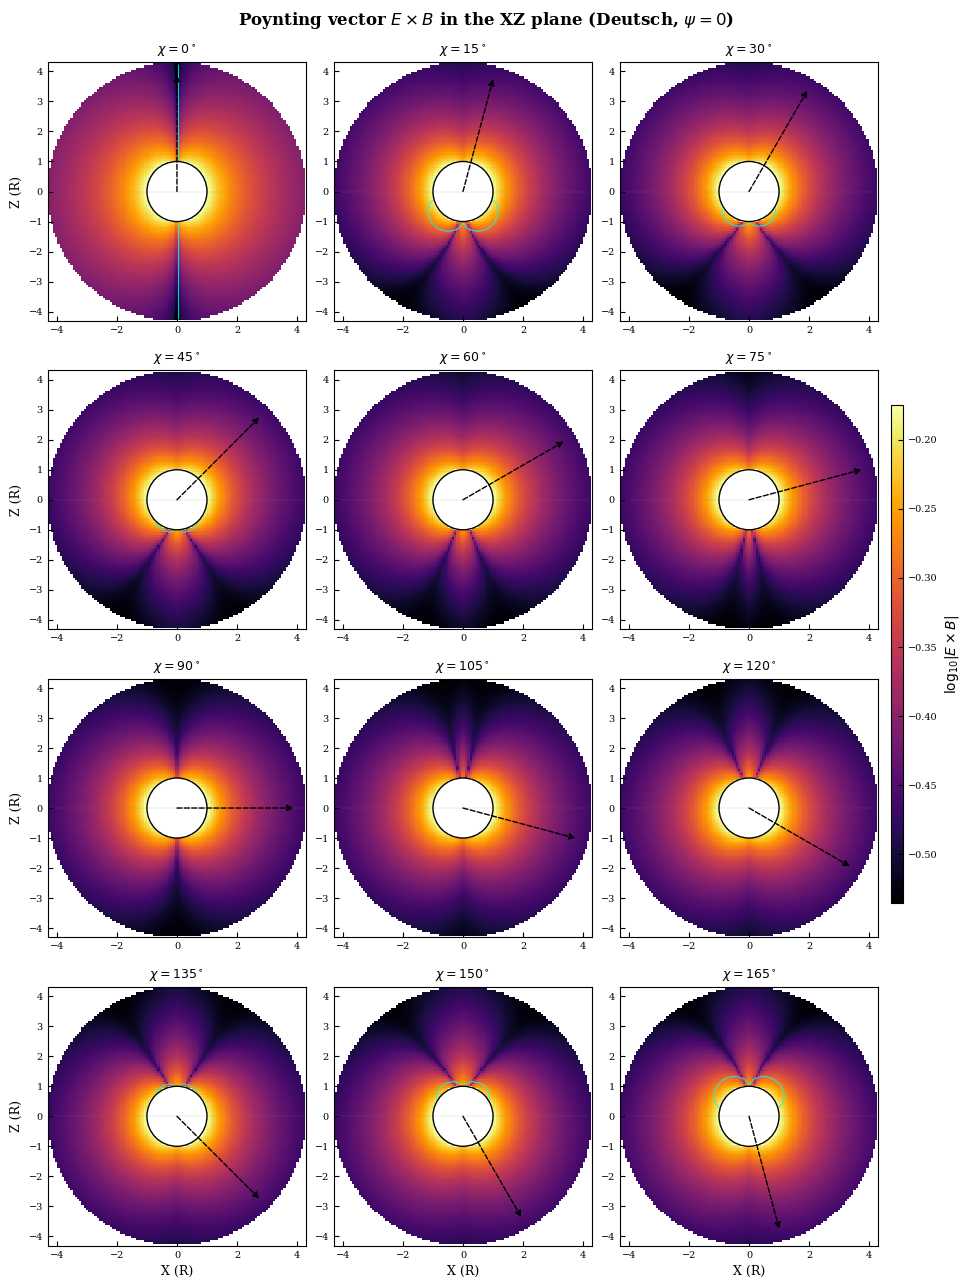

Salvo: poynting_grid.pdf


In [1]:
# =========================================================
# VETOR DE POYNTING E×B — grade 4×3, ângulos 0 a 165
# Painel 1: log10|E×B|  (magnitude do fluxo)
# Painel 2: S_r/|S|    (direção radial: + = para fora)
# =========================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

import simulation
from simulation import EM_Deutsch, R, r_lc

plt.rcParams.update({
    'font.size': 8, 'font.family': 'serif',
    'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
})

# =========================================================
# CONFIGURAÇÃO
# =========================================================
ANGLES  = [0, 15, 30, 45, 60, 75,
           90, 105, 120, 135, 150, 165]
NGRID   = 120
R_MIN   = 1.02
R_MAX   = 0.9 * r_lc
OUT_PDF = "poynting_grid.pdf"

# =========================================================
# AVALIAÇÃO DE E×B EM GRADE 2D (plano XZ)
# =========================================================
def poynting_map(angle_deg, n=NGRID, r_min=R_MIN, r_max=R_MAX):
    """
    Retorna X, Z, Smag (|E×B|), Sr_norm (S_r/|S|).
    """
    x = np.linspace(-r_max, r_max, n)
    z = np.linspace(-r_max, r_max, n)
    X, Z = np.meshgrid(x, z)
    Y = np.zeros_like(X)

    r = np.sqrt(X**2 + Y**2 + Z**2)
    inside = (r >= r_min) & (r <= r_max)

    Smag    = np.full_like(X, np.nan)
    Sr_norm = np.full_like(X, np.nan)
    Xt = np.radians(angle_deg)

    for i in range(n):
        for j in range(n):
            if not inside[i, j]:
                continue
            xi, zi = X[i, j], Z[i, j]
            ex, ey, ez, bx, by, bz = EM_Deutsch(xi, 0.0, zi, 0.0, Xt)
            E = np.array([ex, ey, ez])
            B = np.array([bx, by, bz])
            S = np.cross(E, B)        # E×B
            nS = np.linalg.norm(S)
            Smag[i, j] = nS
            if nS > 0:
                # componente radial de S (no plano XZ, r̂ = (x,0,z)/r)
                rhat_x = xi / r[i, j]
                rhat_z = zi / r[i, j]
                Sr = S[0] * rhat_x + S[2] * rhat_z
                Sr_norm[i, j] = Sr / nS
    return X, Z, Smag, Sr_norm

# =========================================================
# PLOT — 2 grades 4×3 (magnitude e direção)
# =========================================================
N_ROWS = 4
N_COLS = 3

fig, axes = plt.subplots(N_ROWS, N_COLS,
                          figsize=(3.2 * N_COLS, 3.2 * N_ROWS),
                          constrained_layout=True)
axes = axes.ravel()

# Guarda os mapas para colorbars globais
all_Smag = []
all_Sr   = []

theta_circ = np.linspace(0, 2*np.pi, 400)

for k, ang in enumerate(ANGLES):
    ax = axes[k]
    X, Z, Smag, Sr_norm = poynting_map(ang)
    all_Smag.append(np.nanmax(Smag))
    all_Sr.append(np.nanmax(np.abs(Sr_norm)))

    # pcolormesh com |E×B| em escala log
    im = ax.pcolormesh(X, Z, np.log10(Smag + 1e-30),
                       shading="auto", cmap="inferno",
                       rasterized=True)

    # Sobreposição: contornos de S_r = 0 (fronteira entre fluxo para fora e para dentro)
    cs = ax.contour(X, Z, Sr_norm, levels=[0],
                    colors="cyan", linewidths=0.8, alpha=0.8)

    # Estrela
    ax.add_patch(plt.Circle((0, 0), R, color="k", fill=False, lw=1.0,
                            zorder=4))

    # Eixo magnético (seta)
    chi_rad = np.radians(ang)
    L = R_MAX * 0.9
    arrow = FancyArrowPatch(
        (0, 0), (L*np.sin(chi_rad), L*np.cos(chi_rad)),
        arrowstyle='-|>', color='k', lw=1.0, ls='--',
        mutation_scale=9, shrinkA=0, shrinkB=0, zorder=5,
    )
    ax.add_patch(arrow)

    ax.axhline(0, color='gray', lw=0.3, ls=':', zorder=2)

    # Estética
    ax.set_aspect("equal")
    ax.set_xlim(-R_MAX, R_MAX)
    ax.set_ylim(-R_MAX, R_MAX)
    ax.set_title(rf"$\chi = {ang}^\circ$", fontsize=9)
    ax.tick_params(labelsize=7)
    if k % N_COLS == 0:
        ax.set_ylabel("Z (R)")
    if k >= (N_ROWS - 1) * N_COLS:
        ax.set_xlabel("X (R)")

# Colorbar global para log10|E×B|
sm = plt.cm.ScalarMappable(
    cmap="inferno",
    norm=Normalize(vmin=np.log10(np.nanmin([s for s in all_Smag if s > 0])),
                   vmax=np.log10(np.nanmax(all_Smag)))
)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, fraction=0.015, pad=0.015, aspect=40)
cbar.set_label(r"$\log_{10}|E\times B|$", fontsize=10)

fig.suptitle(r"Poynting vector $E\times B$ in the XZ plane "
             r"(Deutsch, $\psi=0$)", fontsize=12, fontweight='bold')

plt.savefig(OUT_PDF, bbox_inches="tight", pad_inches=0.05)
plt.show()
print(f"Salvo: {OUT_PDF}")

Ejetadas both totais: 339
Com sin(phi) < 0.342 (|φ|<20.0°): 78
rho_plane range: 0.487 / 4.047
z_plane range:   1.010 / 3.835
R_MAX = 4.306


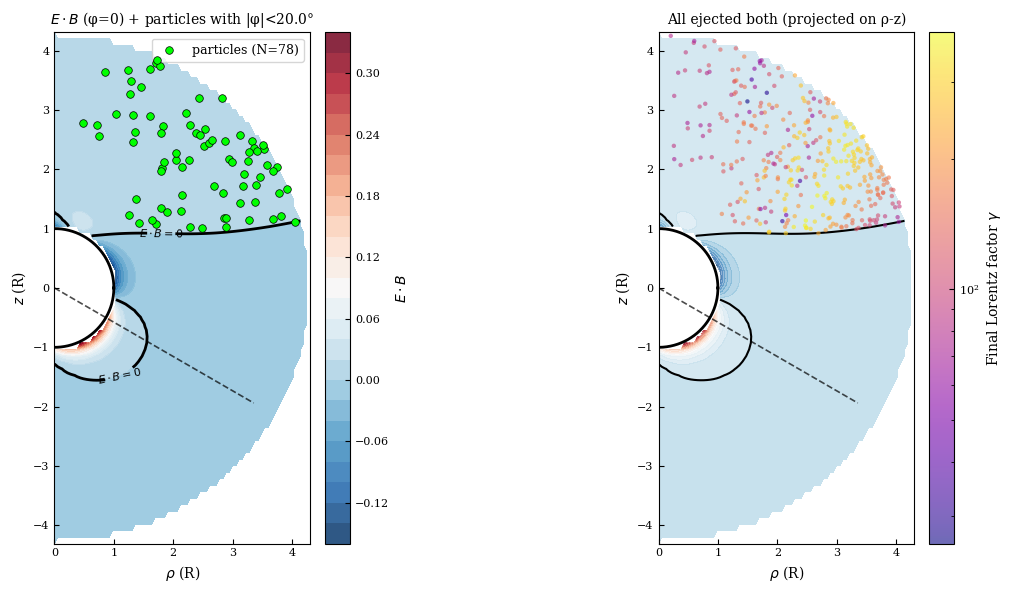

Salvo.


In [26]:
# =========================================================
# E·B no plano φ=0 + partículas ejetadas do HS
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import simulation
from simulation import EM_Deutsch, r_lc

# ---------- Configuração ----------
CSV_FILE   = "particles_all_runs.csv"
ALPHA_VAL  = 10000
ANGLE_DEG  = 120
PHI_WIDTH  = 20.0      # tolerância em φ (graus)
HEMISPHERE = "both"
POSITION   = "initial" # "initial" ou "final"

# ---------- Grade E·B ----------
Xt = np.radians(ANGLE_DEG)
R_MIN = 1.02
R_MAX = 0.9 * r_lc
NGRID = 80

rhos = np.linspace(0, R_MAX, NGRID)   # ρ de 0 a R_MAX
zs = np.linspace(-R_MAX, R_MAX, NGRID)
RHO, ZZ = np.meshgrid(rhos, zs)
XX = RHO
YY = np.zeros_like(RHO)

r2 = np.sqrt(XX**2 + YY**2 + ZZ**2)
inside2 = (r2 >= R_MIN) & (r2 <= R_MAX)

EB2 = np.full_like(XX, np.nan)
for i in range(NGRID):
    for j in range(NGRID):
        if not inside2[i, j]:
            continue
        ex, ey, ez, bx, by, bz = EM_Deutsch(XX[i,j], YY[i,j], ZZ[i,j], 0.0, Xt)
        EB2[i,j] = ex*bx + ey*by + ez*bz

# ---------- Partículas ----------
df = pd.read_csv(CSV_FILE)
d = df[(df.angle_deg == ANGLE_DEG) &
       (df.alpha == ALPHA_VAL) &
       (df.status == "Ejected")].copy()

if HEMISPHERE == "S":
    d = d[d.z0 < 0]
elif HEMISPHERE == "N":
    d = d[d.z0 > 0]

# Escolhe colunas
if POSITION == "initial":
    x_ = d.x0.values; y_ = d.y0.values; z_ = d.z0.values
else:
    x_ = d.xf.values; y_ = d.yf.values; z_ = d.zf.values

# Calcula ρ e sin(phi)
rho_ = np.sqrt(x_**2 + y_**2)
sin_phi_ = np.abs(y_) / (rho_ + 1e-30)

# Filtro: partículas no plano φ≈0
sin_threshold = np.sin(np.radians(PHI_WIDTH))
mask_plane = sin_phi_ < sin_threshold

x_plane = x_[mask_plane]
y_plane = y_[mask_plane]
z_plane = z_[mask_plane]
rho_plane = rho_[mask_plane]
gamma_plane = d.gamma_final.values[mask_plane]

print(f"Ejetadas {HEMISPHERE} totais: {len(d)}")
print(f"Com sin(phi) < {sin_threshold:.3f} (|φ|<{PHI_WIDTH}°): {len(x_plane)}")
print(f"rho_plane range: {rho_plane.min():.3f} / {rho_plane.max():.3f}")
print(f"z_plane range:   {z_plane.min():.3f} / {z_plane.max():.3f}")
print(f"R_MAX = {R_MAX:.3f}")

# ---------- Plot ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Painel 1: E·B + partículas no plano
ax = axes[0]
cf = ax.contourf(RHO, ZZ, EB2, levels=30, cmap='RdBu_r', alpha=0.85)
cs = ax.contour(RHO, ZZ, EB2, levels=[0], colors='black', linewidths=2)
ax.clabel(cs, fmt=r"$E\cdot B=0$", fontsize=8)

if len(x_plane) > 0:
    gmin = max(gamma_plane.min(), 1.0)
    gmax = gamma_plane.max() * 1.001
    sc = ax.scatter(rho_plane, z_plane, c='lime', s=30,
                    edgecolors='black', linewidths=0.5,
                    zorder=10, label=f'particles (N={len(x_plane)})')
    ax.legend(loc='upper right', fontsize=9)

# Estrela
th = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(th), np.sin(th), 'k-', lw=2, zorder=6)

# Eixo magnético
L = R_MAX * 0.9
ax.plot([0, L*np.sin(Xt)], [0, L*np.cos(Xt)], 'k--', lw=1.2, alpha=0.7)
ax.plot([0, -L*np.sin(Xt)], [0, -L*np.cos(Xt)], 'k--', lw=1.2, alpha=0.7)

ax.set_aspect('equal')
ax.set_xlim(0, R_MAX)
ax.set_ylim(-R_MAX, R_MAX)
ax.set_xlabel(r'$\rho$ (R)'); ax.set_ylabel(r'$z$ (R)')
ax.set_title(rf'$E\cdot B$ (φ=0) + particles with |φ|<{PHI_WIDTH}°')
cbar = plt.colorbar(cf, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label(r'$E\cdot B$')

# Painel 2: TODAS as ejetadas do HS, projetadas em (ρ, z)
ax = axes[1]
cf2 = ax.contourf(RHO, ZZ, EB2, levels=30, cmap='RdBu_r', alpha=0.5)
cs2 = ax.contour(RHO, ZZ, EB2, levels=[0], colors='black', linewidths=1.5)

# Todas as partículas (sem filtro de φ)
rho_all = np.sqrt(x_**2 + y_**2)
gamma_all = d.gamma_final.values
sc2 = ax.scatter(rho_all, z_, c=gamma_all, cmap='plasma',
                 norm=LogNorm(vmin=max(gamma_all.min(), 1.0),
                              vmax=gamma_all.max() * 1.001),
                 s=10, alpha=0.6, edgecolors='none', zorder=10)
plt.colorbar(sc2, ax=ax, fraction=0.04, pad=0.02,
             label=r'Final Lorentz factor $\gamma$')

th = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(th), np.sin(th), 'k-', lw=2, zorder=6)
ax.plot([0, L*np.sin(Xt)], [0, L*np.cos(Xt)], 'k--', lw=1.2, alpha=0.7)
ax.plot([0, -L*np.sin(Xt)], [0, -L*np.cos(Xt)], 'k--', lw=1.2, alpha=0.7)

ax.set_aspect('equal')
ax.set_xlim(0, R_MAX)
ax.set_ylim(-R_MAX, R_MAX)
ax.set_xlabel(r'$\rho$ (R)'); ax.set_ylabel(r'$z$ (R)')
ax.set_title(f'All ejected {HEMISPHERE} (projected on ρ-z)')

plt.tight_layout()
plt.savefig(f'EB_with_particles_chi{ANGLE_DEG}_alpha{ALPHA_VAL}.pdf',
            bbox_inches='tight', pad_inches=0.05)
plt.show()
print("Salvo.")

In [22]:
# =========================================================
# HOTSPOTS 3D — partículas que crasharam na estrela
# χ = 180°, com a estrela como esfera 3D
# =========================================================
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# ---------- Configuração ----------
CSV_FILE   = "particles_all_runs.csv"
ALPHA_VAL  = 10000
ANGLE_DEG  = 135
STATUS     = "Crashed"
R_STAR     = 1.0

# ---------- Carrega ----------
df = pd.read_csv(CSV_FILE)
d = df[(df.angle_deg == ANGLE_DEG) &
       (df.alpha == ALPHA_VAL) &
       (df.status == STATUS)].copy()

print(f"Partículas {STATUS} em χ={ANGLE_DEG}°, α={ALPHA_VAL}: {len(d)}")

if len(d) == 0:
    raise ValueError("Nenhuma partícula encontrada. Ajuste os filtros.")

# ---------- Coordenadas das partículas ----------
# Para Crashed, a posição final é sobre a superfície da estrela (r ≈ R)
xf = d.xf.values
yf = d.yf.values
zf = d.zf.values
gamma = d.gamma_final.values

# Normaliza para garantir que os pontos estão exatamente em r = R
r = np.sqrt(xf**2 + yf**2 + zf**2)
xf_n = xf / r * R_STAR
yf_n = yf / r * R_STAR
zf_n = zf / r * R_STAR

# Coordenadas esféricas para estatística
theta_f = np.degrees(np.arccos(np.clip(zf_n / R_STAR, -1, 1)))
phi_f   = np.degrees(np.arctan2(yf_n, xf_n))

print(f"θ_f mediana: {np.median(theta_f):.1f}°")
print(f"θ_f range:   {theta_f.min():.1f}° / {theta_f.max():.1f}°")
print(f"Fracção no HN (θ_f < 90°): {(theta_f < 90).mean():.3f}")
print(f"Fracção no HS (θ_f > 90°): {(theta_f > 90).mean():.3f}")

# =========================================================
# FIGURA
# =========================================================
fig = go.Figure()

# ---------- Estrela 3D ----------
u, v = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
xs = R_STAR * np.cos(u) * np.sin(v)
ys = R_STAR * np.sin(u) * np.sin(v)
zs = R_STAR * np.cos(v)

fig.add_trace(go.Surface(
    x=xs, y=ys, z=zs,
    colorscale=[[0, 'lightgray'], [1, 'lightgray']],
    showscale=False,
    opacity=0.9,
    name='star',
    hoverinfo='skip',
    lighting=dict(ambient=0.7, diffuse=0.6, specular=0.1),
))

# ---------- Partículas que crasharam ----------
log_gamma = np.log10(np.clip(gamma, 1, None))

fig.add_trace(go.Scatter3d(
    x=xf_n, y=yf_n, z=zf_n,
    mode='markers',
    marker=dict(
        size=5,
        color=log_gamma,
        colorscale='Plasma',
        cmin=log_gamma.min(),
        cmax=log_gamma.max(),
        colorbar=dict(title=r'log10(γ)', thickness=15, len=0.6),
        opacity=0.85,
        line=dict(width=0),
    ),
    name=f'{STATUS} (N={len(d)})',
    text=[f"θ={t:.1f}°, φ={p:.1f}°, γ={g:.1f}"
          for t, p, g in zip(theta_f, phi_f, gamma)],
    hovertemplate="x: %{x:.3f}<br>y: %{y:.3f}<br>z: %{z:.3f}<br>%{text}<extra></extra>",
))

# ---------- Eixos ----------
L = 1.5
fig.add_trace(go.Scatter3d(
    x=[0, 0], y=[0, 0], z=[-L, L],
    mode='lines',
    line=dict(color='black', width=4, dash='dot'),
    name='rotation axis (z)',
))

Xt = np.radians(ANGLE_DEG)
fig.add_trace(go.Scatter3d(
    x=[-L*np.sin(Xt), L*np.sin(Xt)],
    y=[0, 0],
    z=[-L*np.cos(Xt), L*np.cos(Xt)],
    mode='lines',
    line=dict(color='red', width=5, dash='dash'),
    name=f'magnetic axis (χ={ANGLE_DEG}°)',
))

# Eixos X, Y, Z como linhas guia
for vec, col, name in [((1,0,0), 'blue', 'X'),
                        ((0,1,0), 'green', 'Y')]:
    fig.add_trace(go.Scatter3d(
        x=[-vec[0]*L, vec[0]*L],
        y=[-vec[1]*L, vec[1]*L],
        z=[-vec[2]*L, vec[2]*L],
        mode='lines',
        line=dict(color=col, width=2, dash='dot'),
        opacity=0.3,
        name=f'{name} axis',
    ))

# =========================================================
# LAYOUT
# =========================================================
fig.update_layout(
    scene=dict(
        xaxis=dict(title='X (R)', range=[-L, L]),
        yaxis=dict(title='Y (R)', range=[-L, L]),
        zaxis=dict(title='Z (R)', range=[-L, L]),
        aspectmode='cube',
        camera=dict(eye=dict(x=1.6, y=1.6, z=1.0)),
    ),
    title=dict(
        text=f'Impact hotspots on the stellar surface — '
             f'χ = {ANGLE_DEG}°, α = {ALPHA_VAL}  (N = {len(d)})',
        x=0.5,
    ),
    width=950, height=900,
    legend=dict(x=0.02, y=0.98, bgcolor='rgba(255,255,255,0.85)'),
)

fig.show()

Partículas Crashed em χ=135°, α=10000: 324
θ_f mediana: 111.4°
θ_f range:   0.8° / 119.6°
Fracção no HN (θ_f < 90°): 0.062
Fracção no HS (θ_f > 90°): 0.938


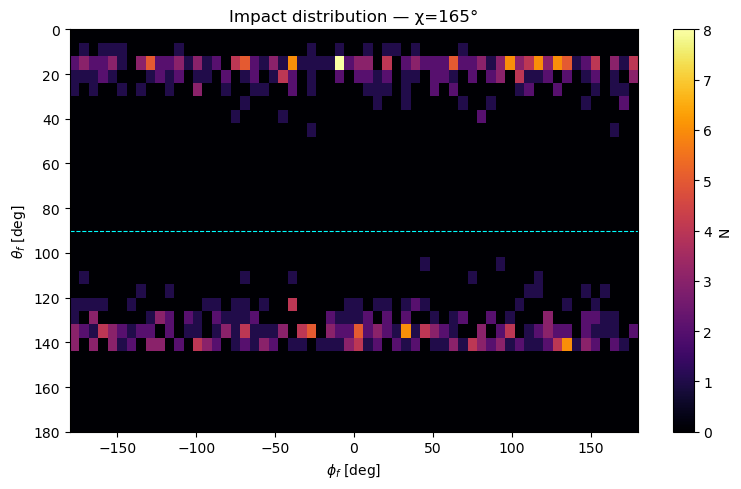

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
h = ax.hist2d(phi_f, theta_f, bins=[60, 30],
              range=[[-180, 180], [0, 180]],
              cmap='inferno')
ax.set_xlabel(r'$\phi_f$ [deg]')
ax.set_ylabel(r'$\theta_f$ [deg]')
ax.invert_yaxis()   # polo norte em cima
ax.axhline(90, color='cyan', lw=0.8, ls='--')
plt.colorbar(h[3], ax=ax, label='N')
ax.set_title(f'Impact distribution — χ={ANGLE_DEG}°')
plt.tight_layout(); plt.show()